<a href="https://colab.research.google.com/github/nurilhuda05/PCVK_Ganjil_2026/blob/main/P9_17_Muhammad_Nuril_Huda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CELL IDENTITAS**

In [95]:
NAMA = 'Muhammad Nuril Huda'
NIM = '244107020004'
print(NAMA, NIM)

Muhammad Nuril Huda 244107020004


# **GAMBAR PLAT NOMOR BINER**

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


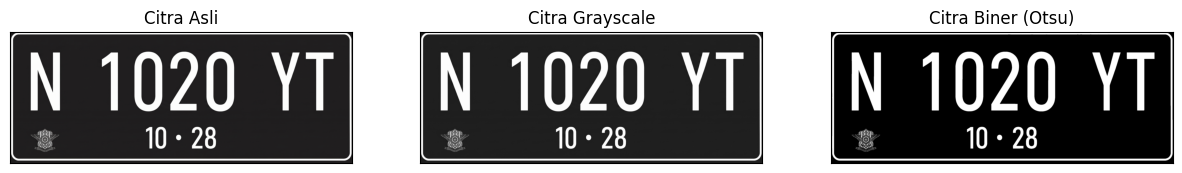

In [96]:
import cv2
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

# Membaca gambar plat nomor dalam grayscale
img_plat_nomor = cv2.imread('/content/drive/MyDrive/Semester 5/PCVK/images/plat_nomor.jpeg')

# Mengubah gambar menjadi grayscale
gray_plat_nomor = cv2.cvtColor(img_plat_nomor, cv2.COLOR_BGR2GRAY)

# Mengubah gambar grayscale menjadi citra biner menggunakan Otsu
ret, plat_nomor = cv2.threshold(gray_plat_nomor, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(cv2.cvtColor(img_plat_nomor, cv2.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(gray_plat_nomor, cmap='gray')
plt.title('Citra Grayscale')
plt.xticks([])
plt.yticks([])

plt.subplot(133)
plt.imshow(plat_nomor, cmap='gray')
plt.title('Citra Biner (Otsu)')
plt.xticks([])
plt.yticks([])

plt.show()

# **GAMBAR NOISY TEXT BINER**

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


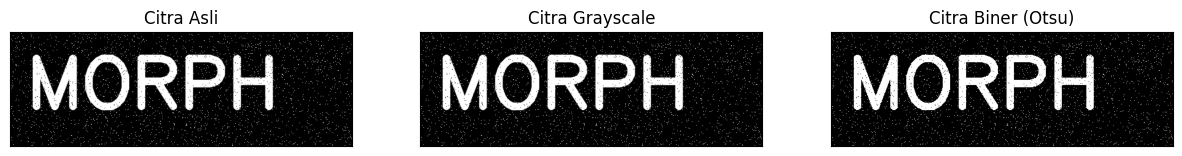

In [97]:
import cv2
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')

# Membaca gambar noisy text dalam grayscale
img_noisy_text = cv2.imread('/content/drive/MyDrive/Semester 5/PCVK/images/noisy_text.png')

# Mengubah gambar menjadi grayscale
gray_noisy_text= cv2.cvtColor(img_noisy_text, cv2.COLOR_BGR2GRAY)

# Mengubah gambar grayscale menjadi citra biner menggunakan Otsu
ret, noisy_text = cv2.threshold(gray_noisy_text, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.imshow(cv2.cvtColor(img_noisy_text, cv2.COLOR_BGR2RGB))
plt.title('Citra Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(gray_noisy_text, cmap='gray')
plt.title('Citra Grayscale')
plt.xticks([])
plt.yticks([])

plt.subplot(133)
plt.imshow(noisy_text, cmap='gray')
plt.title('Citra Biner (Otsu)')
plt.xticks([])
plt.yticks([])

plt.show()

# **D. PRAKTIKUM MORFOLOGI**

### **1. Menghubungkan Dengan Google Drive**

In [98]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **2. Import Library**

In [99]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

### **3. Membuat Fungsi Dilasi Tanpa Library Morphology**

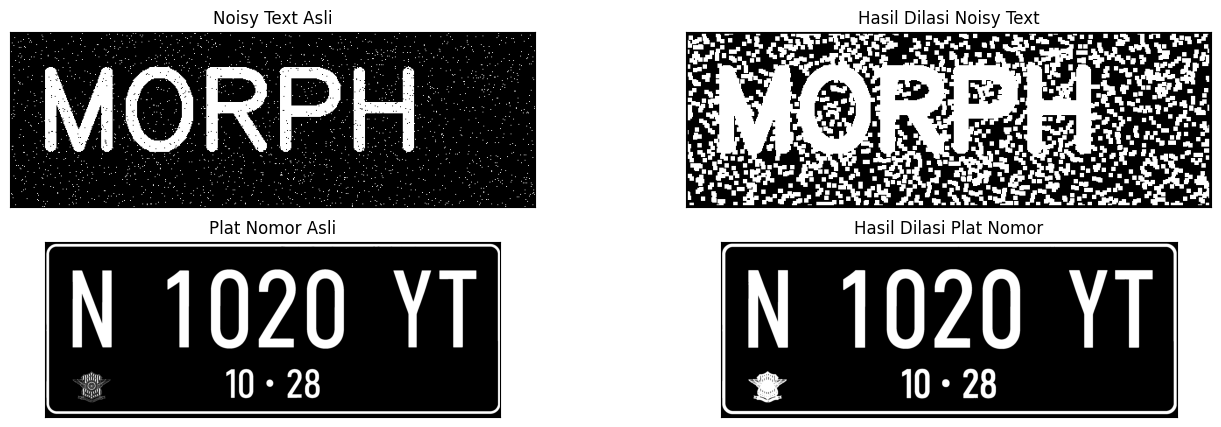

In [100]:
def dilasi_citra(F,w):
  #size image
  p,q= F.shape

  imgD= np.zeros((p,q), dtype=np.uint8)

  # Generate structure element dilasi (SED)
  SED= np.ones((w,w), dtype=np.uint8)
  constant1= (w-1)//2

  #Proses Dilasi
  for i in range(constant1, p-constant1):
    for j in range(constant1,q-constant1):
      temp= F[i-constant1:i+constant1+1, j-constant1:j+constant1+1]
      product= temp*SED
      imgD[i,j]= np.max(product)
  return imgD


img_noisy_text= noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Dilasi pada noisy_text
w=5
hasil_noisy_text = dilasi_citra(img_noisy_text,w)

# Dilasi pada plat nomor
w=5
hasil_plat_nomor = dilasi_citra(img_plat_nomor,w)

# Menampilkan empat gambar
plt.figure(figsize=(16, 5))

plt.subplot(2,2,1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,2)
plt.imshow(hasil_noisy_text, cmap='gray')
plt.title('Hasil Dilasi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2,2,4)
plt.imshow(hasil_plat_nomor, cmap='gray')
plt.title('Hasil Dilasi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.show()


### **4. Implementasi Dilasi menggunakan Library OpenCV**

[[1 1 1]
 [1 1 1]
 [1 1 1]]


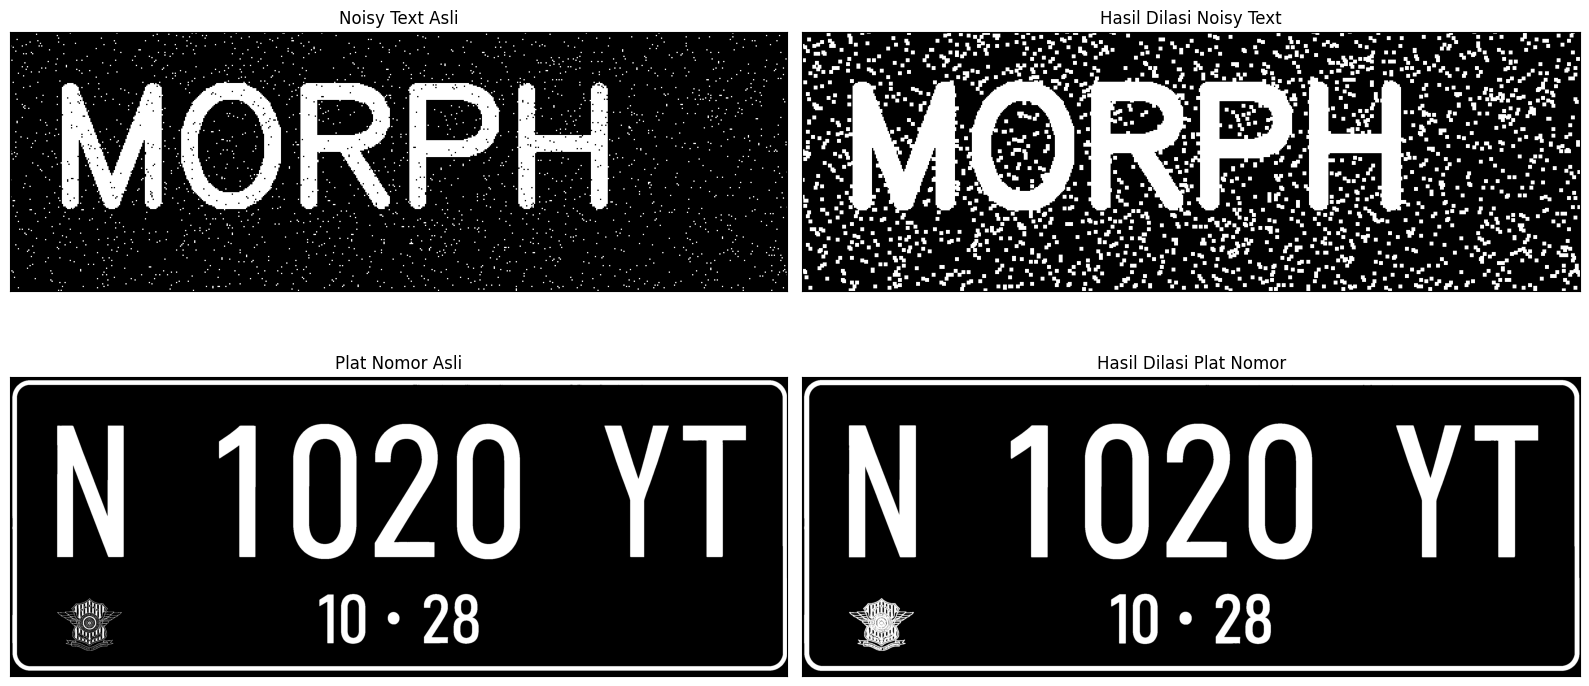

In [101]:
img_noisy_text= noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

kernel = np.ones((3, 3), np.uint16)

# Dilasi pada noisy_text
dilasi_noisy_text = cv2.dilate(img_noisy_text, kernel, iterations=1)

# Dilasi pada plat nomor
dilasi_plat_nomor = cv2.dilate(img_plat_nomor, kernel, iterations=1)

print(kernel)

plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(dilasi_noisy_text, cmap='gray')
plt.title('Hasil Dilasi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(dilasi_plat_nomor, cmap='gray')
plt.title('Hasil Dilasi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **5. Implementasi Erosi Tanpa Library OpenCV**

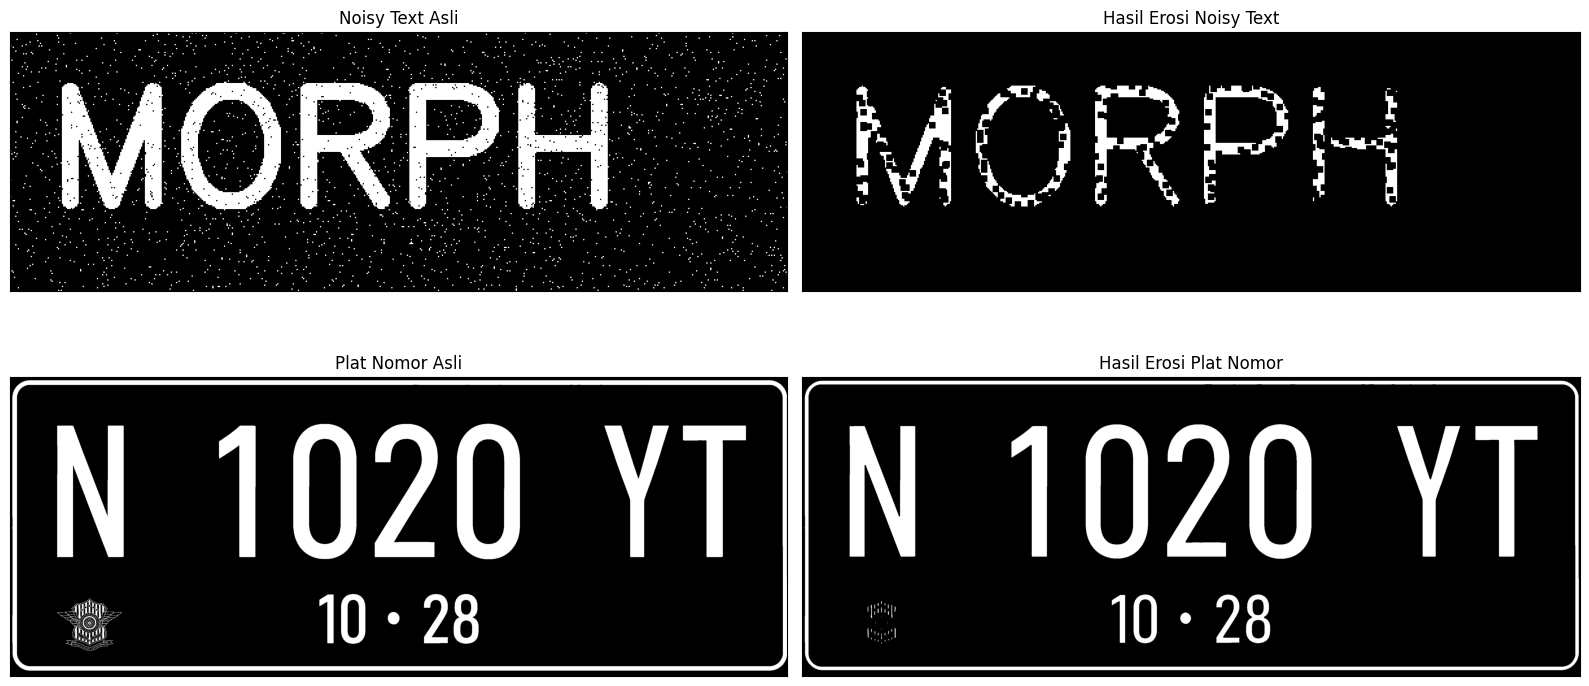

In [102]:
def erosi_citra(F,k):
  # size image
  m,n= F.shape

  # Generate structure element erosi (SE)
  SE= np.ones((k,k), dtype=np.uint8)
  constant= (k-1)//2

  imgE= np.zeros((m,n), dtype=np.uint8)

  # Proses Erosi
  for i in range(constant, m-constant):
    for j in range(constant,n-constant):
      temp= F[i-constant:i+constant+1, j-constant:j+constant+1]
      product= temp*SE
      imgE[i,j]= np.min(product)

  return imgE


img_noisy_text= noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Erosi pada noisy_text
k=5
hasil_erosi_noisy_text = erosi_citra(img_noisy_text,k)

# Erosi pada plat nomor
k=5
hasil_erosi_plat_nomor = erosi_citra(img_plat_nomor,k)


plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(hasil_erosi_noisy_text, cmap='gray')
plt.title('Hasil Erosi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(hasil_erosi_plat_nomor, cmap='gray')
plt.title('Hasil Erosi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **6. Implementasi Erosi Menggunakan Library OpenCV**

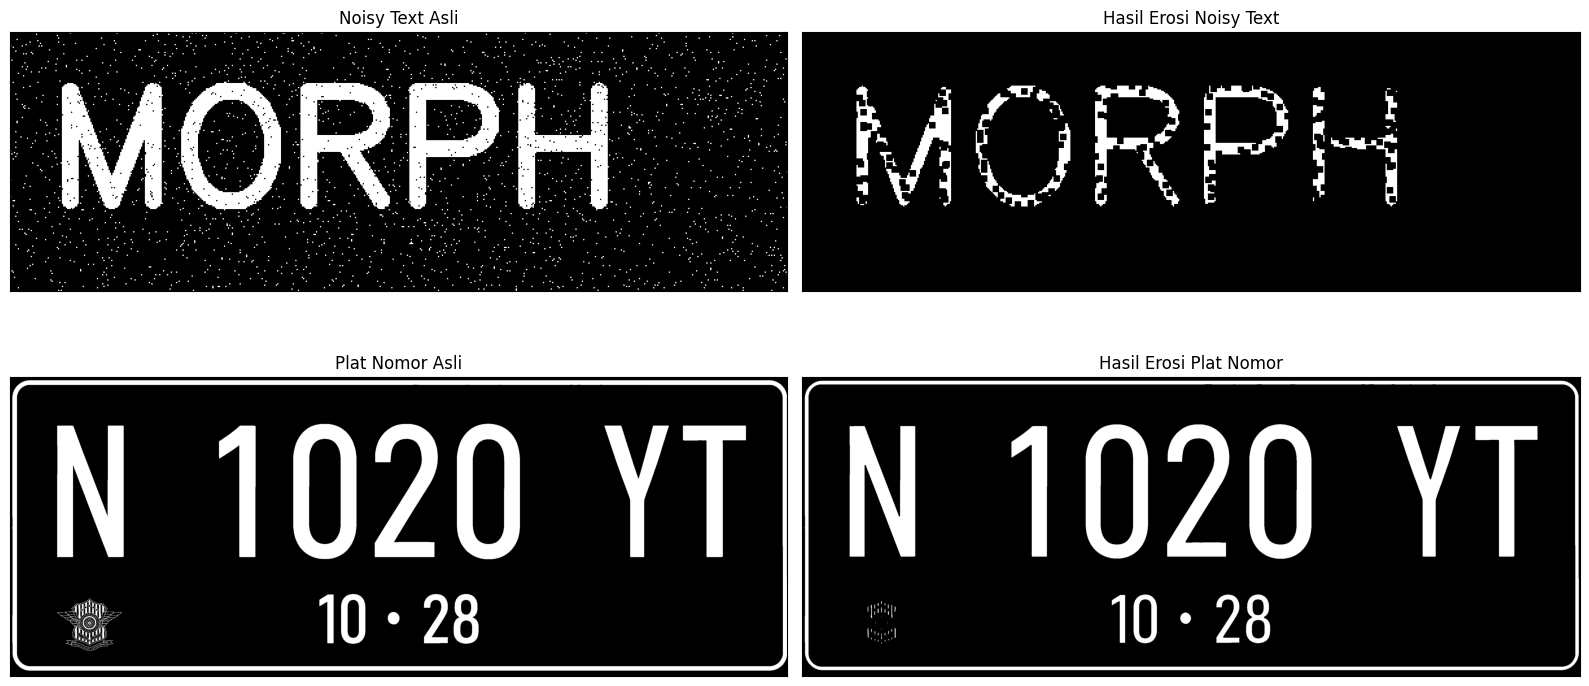

In [103]:
img_noisy_text= noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

kernel = np.ones((5, 5), np.uint8)

# Erosi pada noisy_text
erosi_noisy_text = cv2.erode(img_noisy_text, kernel, iterations=1)

# Erosi pada plat nomor
erosi_plat_nomor = cv2.erode(img_plat_nomor, kernel, iterations=1)

# Menampilkan empat gambar
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(erosi_noisy_text, cmap='gray')
plt.title('Hasil Erosi Noisy Text')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(erosi_plat_nomor, cmap='gray')
plt.title('Hasil Erosi Plat Nomor')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **7. Operasi Opening**

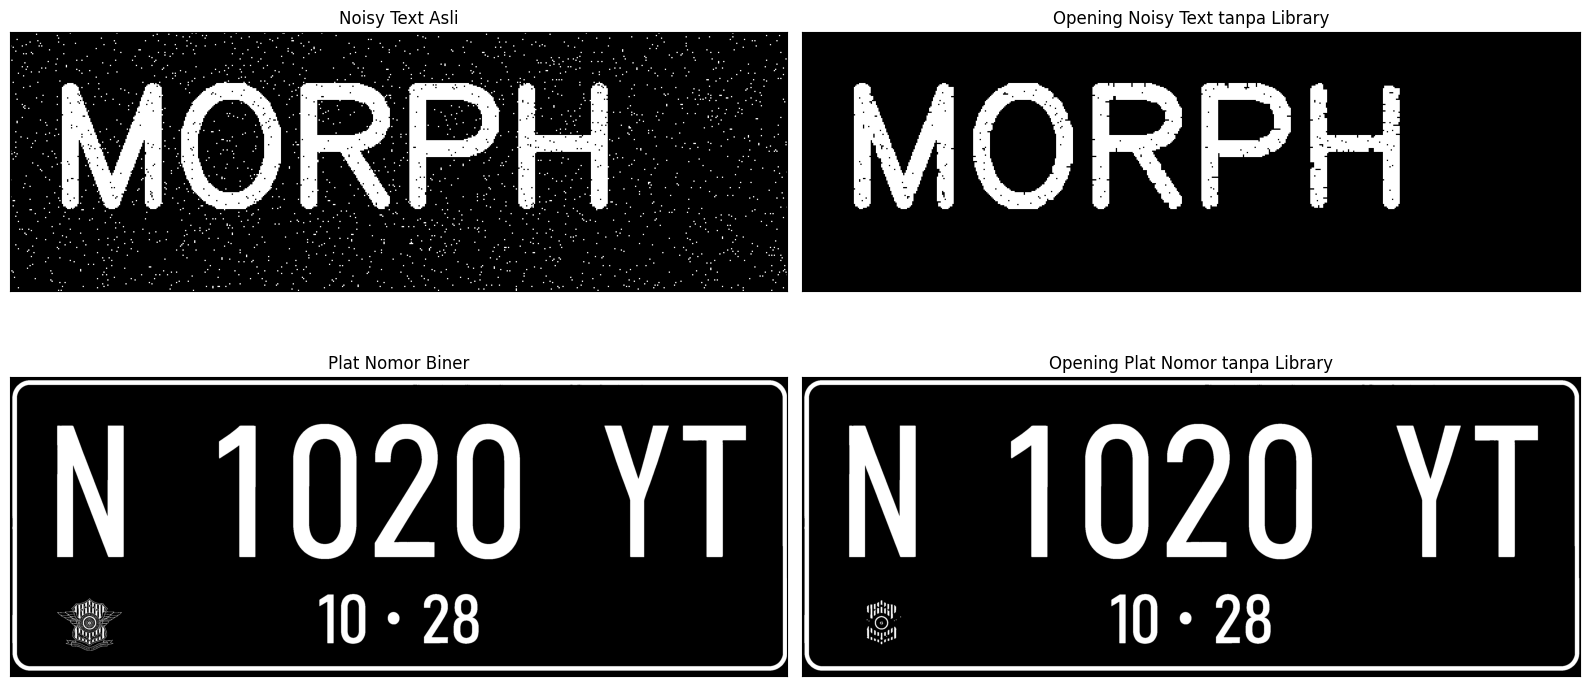

In [104]:
img_noisy_text = noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Operasi Opening tanpa Library Morphology
k = 3

opening_noisy_text_manual = dilasi_citra(erosi_citra(img_noisy_text, k), k)

opening_plat_nomor_manual = dilasi_citra(erosi_citra(img_plat_nomor, k), k)

plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(opening_noisy_text_manual, cmap='gray')
plt.title('Opening Noisy Text tanpa Library')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Biner')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(opening_plat_nomor_manual, cmap='gray')
plt.title('Opening Plat Nomor tanpa Library')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

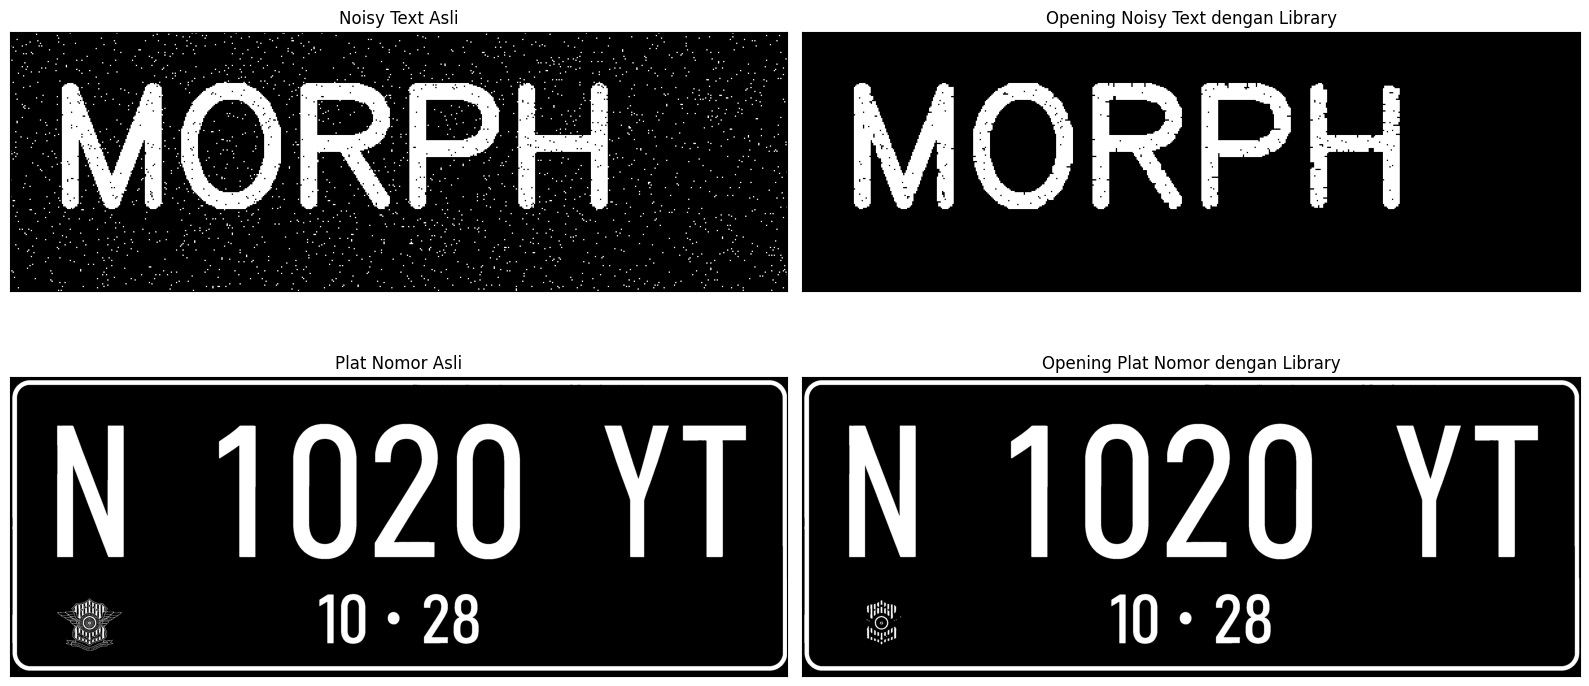

In [105]:
img_noisy_text = noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Operasi Opening Menggunakan Library Morphology

kernel = np.ones((3, 3), np.uint8)

# Opening pada citra noisy_text
opening_noisy_text_library = cv2.morphologyEx(img_noisy_text, cv2.MORPH_OPEN, kernel)

# Opening pada citra plat nomor
opening_plat_nomor_library = cv2.morphologyEx(img_plat_nomor, cv2.MORPH_OPEN, kernel)

plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(opening_noisy_text_library, cmap='gray')
plt.title('Opening Noisy Text dengan Library')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(opening_plat_nomor_library, cmap='gray')
plt.title('Opening Plat Nomor dengan Library')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **8. Operasi Closing**

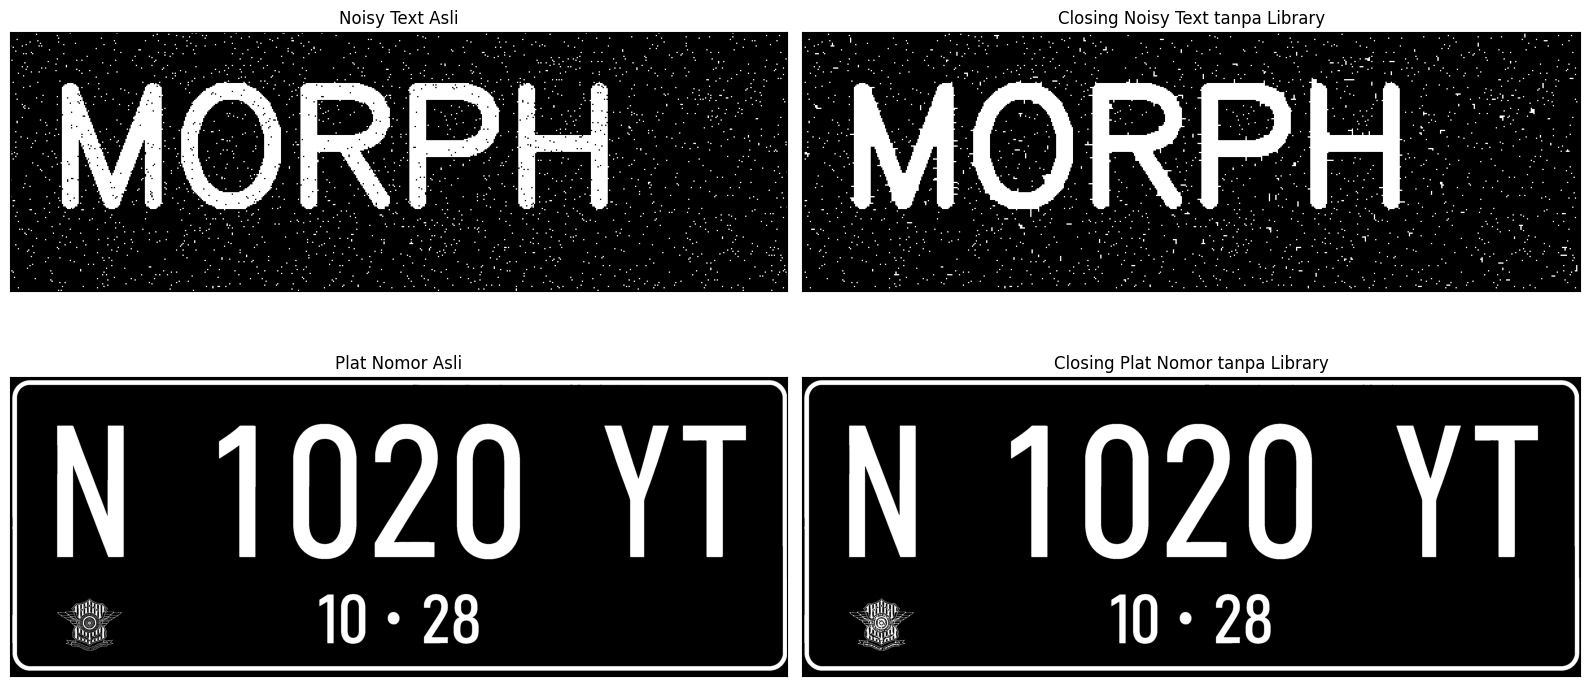

In [106]:
img_noisy_text = noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Operasi Closing tanpa Library Morphology

k = 3

# Closing pada citra noisy_text
closing_noisy_text_manual = erosi_citra(dilasi_citra(img_noisy_text, k), k)

# Closing pada citra plat nomor
closing_plat_nomor_manual = erosi_citra(dilasi_citra(img_plat_nomor, k), k)

plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(closing_noisy_text_manual, cmap='gray')
plt.title('Closing Noisy Text tanpa Library')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(closing_plat_nomor_manual, cmap='gray')
plt.title('Closing Plat Nomor tanpa Library')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

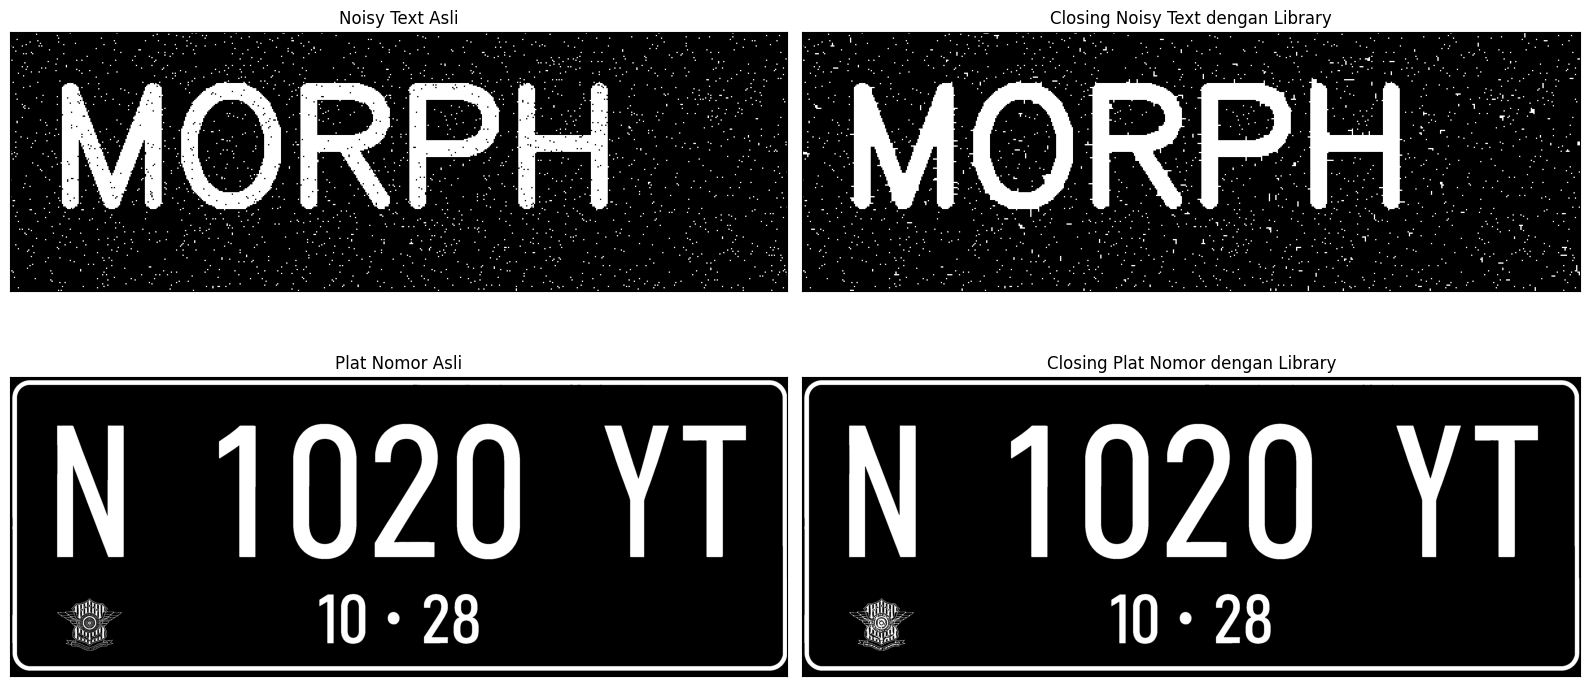

In [107]:
img_noisy_text = noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Operasi Closing dengan Library Morphology

kernel = np.ones((3, 3), np.uint8)

# Closing pada citra noisy_text
closing_noisy_text_library = cv2.morphologyEx(img_noisy_text, cv2.MORPH_CLOSE, kernel)

# Closing pada citra plat nomor
closing_plat_nomor_library = cv2.morphologyEx(img_plat_nomor, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(closing_noisy_text_library, cmap='gray')
plt.title('Closing Noisy Text dengan Library')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(closing_plat_nomor_library, cmap='gray')
plt.title('Closing Plat Nomor dengan Library')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **9. Operasi Dilasi dengan Structuring Element Cross**

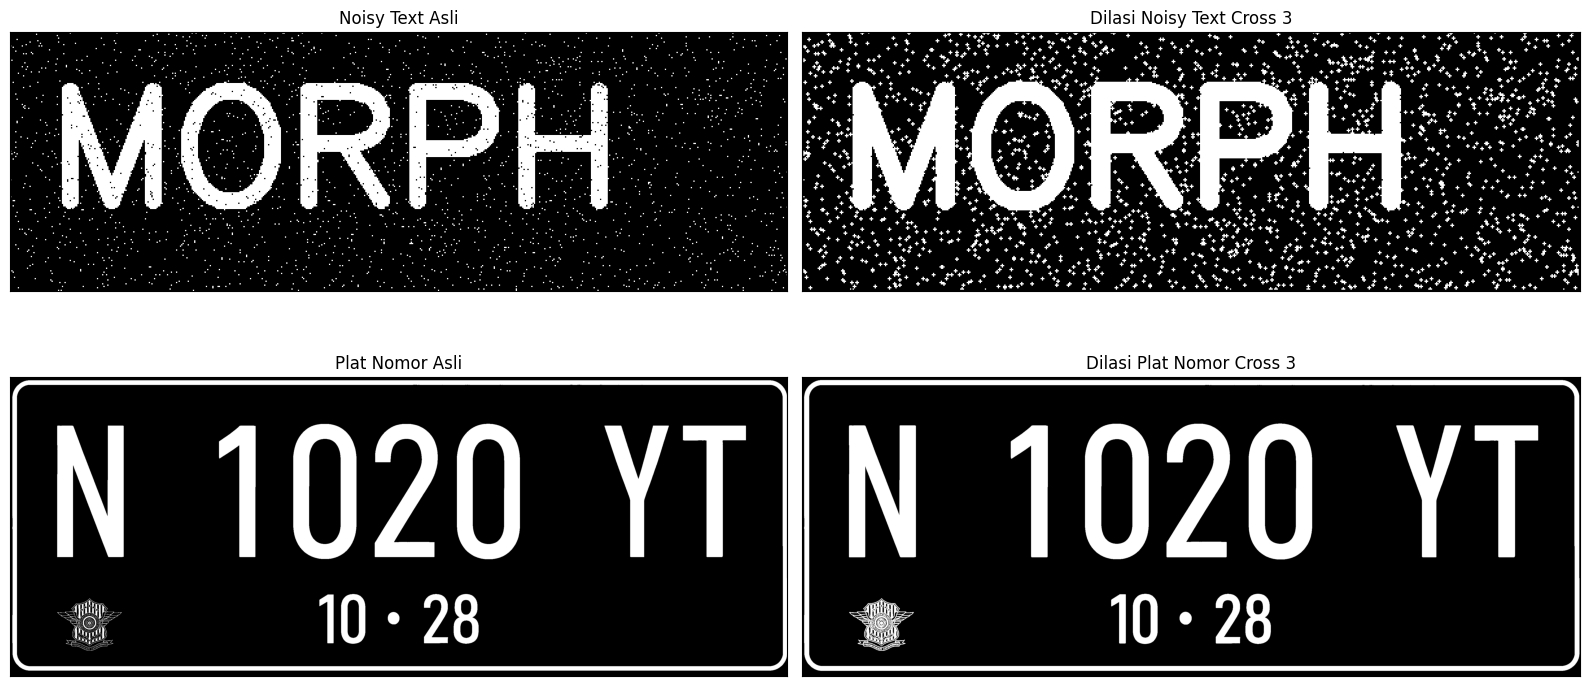

In [108]:
# Dilasi Cross 3

def dilasi_cross(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    SED = np.array([
        [0, 1, 0],
        [1, 1, 1],
        [0, 1, 0]
    ], dtype=np.uint8)

    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i - constant1:i + constant1 + 1,
                j - constant1:j + constant1 + 1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

img_noisy_text = noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Dilasi Cross 3 pada kedua citra
dilasi_noisy_cross3 = dilasi_cross(img_noisy_text, 3)
dilasi_plat_cross3 = dilasi_cross(img_plat_nomor, 3)

# Menampilkan hasil
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(dilasi_noisy_cross3, cmap='gray')
plt.title('Dilasi Noisy Text Cross 3')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(dilasi_plat_cross3, cmap='gray')
plt.title('Dilasi Plat Nomor Cross 3')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

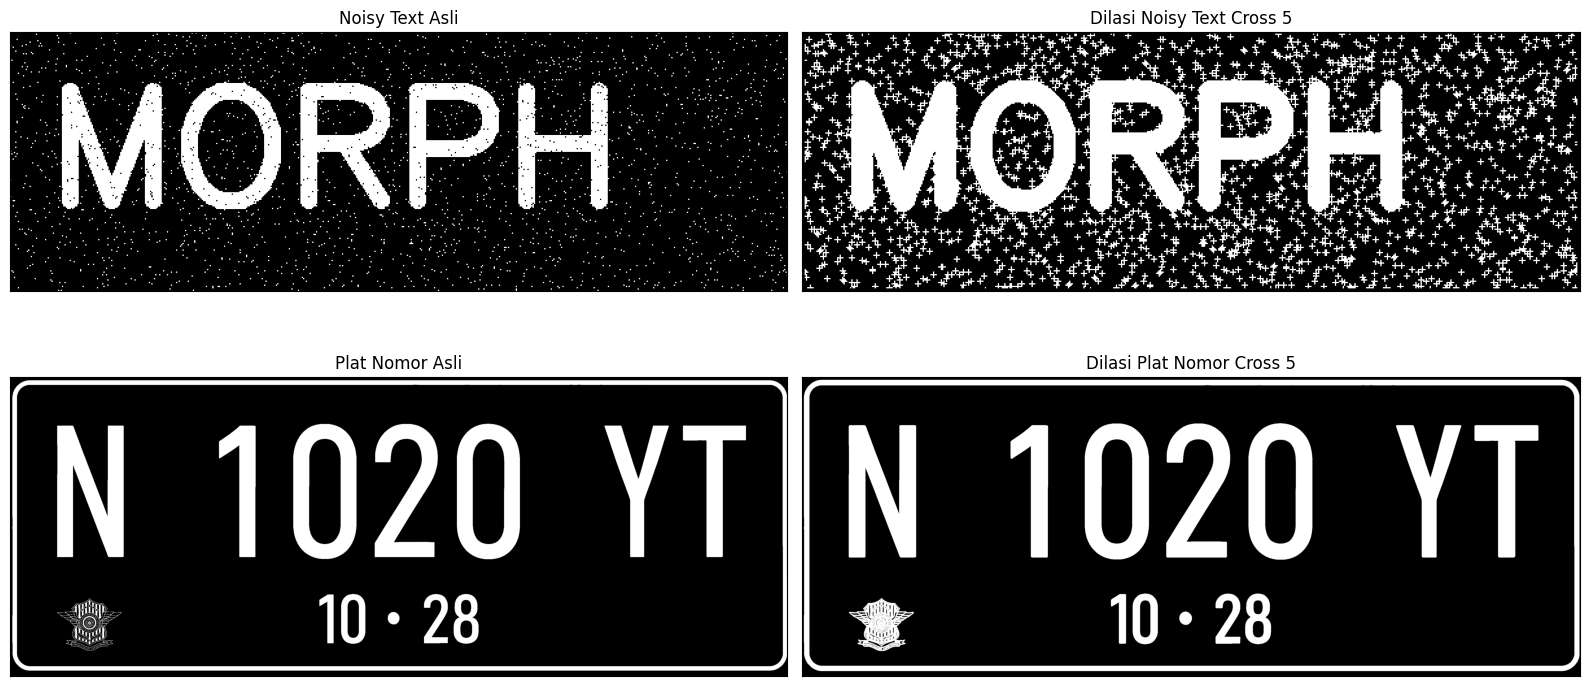

In [109]:
# Dilasi Cross 5

def dilasi_cross(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    SED = np.array([
        [0, 0, 1, 0, 0],
        [0, 0, 1, 0, 0],
        [1, 1, 1, 1, 1],
        [0, 0, 1, 0, 0],
        [0, 0, 1, 0, 0]
    ], dtype=np.uint8)

    constant1 = (w - 1) // 2

    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i - constant1:i + constant1 + 1,
                j - constant1:j + constant1 + 1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD

img_noisy_text = noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Dilasi Cross 5 pada kedua citra
dilasi_noisy_cross5 = dilasi_cross(img_noisy_text, 5)
dilasi_plat_cross5 = dilasi_cross(img_plat_nomor, 5)

# Menampilkan hasil
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(dilasi_noisy_cross5, cmap='gray')
plt.title('Dilasi Noisy Text Cross 5')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(dilasi_plat_cross5, cmap='gray')
plt.title('Dilasi Plat Nomor Cross 5')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **10. Operasi Dilasi dengan Structuring Element Circular**

SED = Circular 3


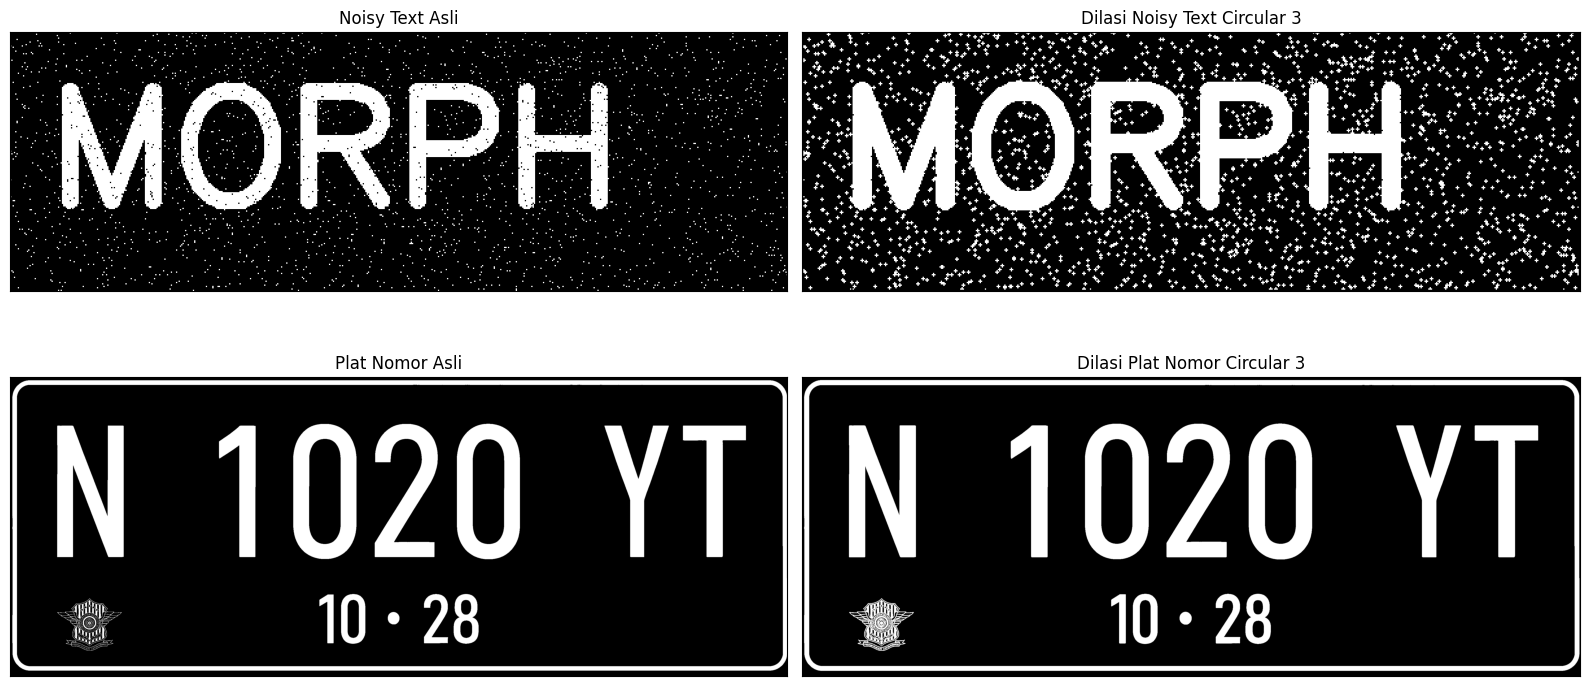

In [110]:
# Dilasi Circular 3 × 3

def dilasi_circular(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate Structuring Element berbentuk Circular
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i - constant1:i + constant1 + 1,
                j - constant1:j + constant1 + 1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


print('SED = Circular 3')

img_noisy_text = noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Dilasi pada kedua citra
w = 3
dilasi_noisy_circular3 = dilasi_circular(img_noisy_text, w)
dilasi_plat_circular3 = dilasi_circular(img_plat_nomor, w)

# Menampilkan hasil
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(dilasi_noisy_circular3, cmap='gray')
plt.title('Dilasi Noisy Text Circular 3')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(dilasi_plat_circular3, cmap='gray')
plt.title('Dilasi Plat Nomor Circular 3')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

SED = Circular 5


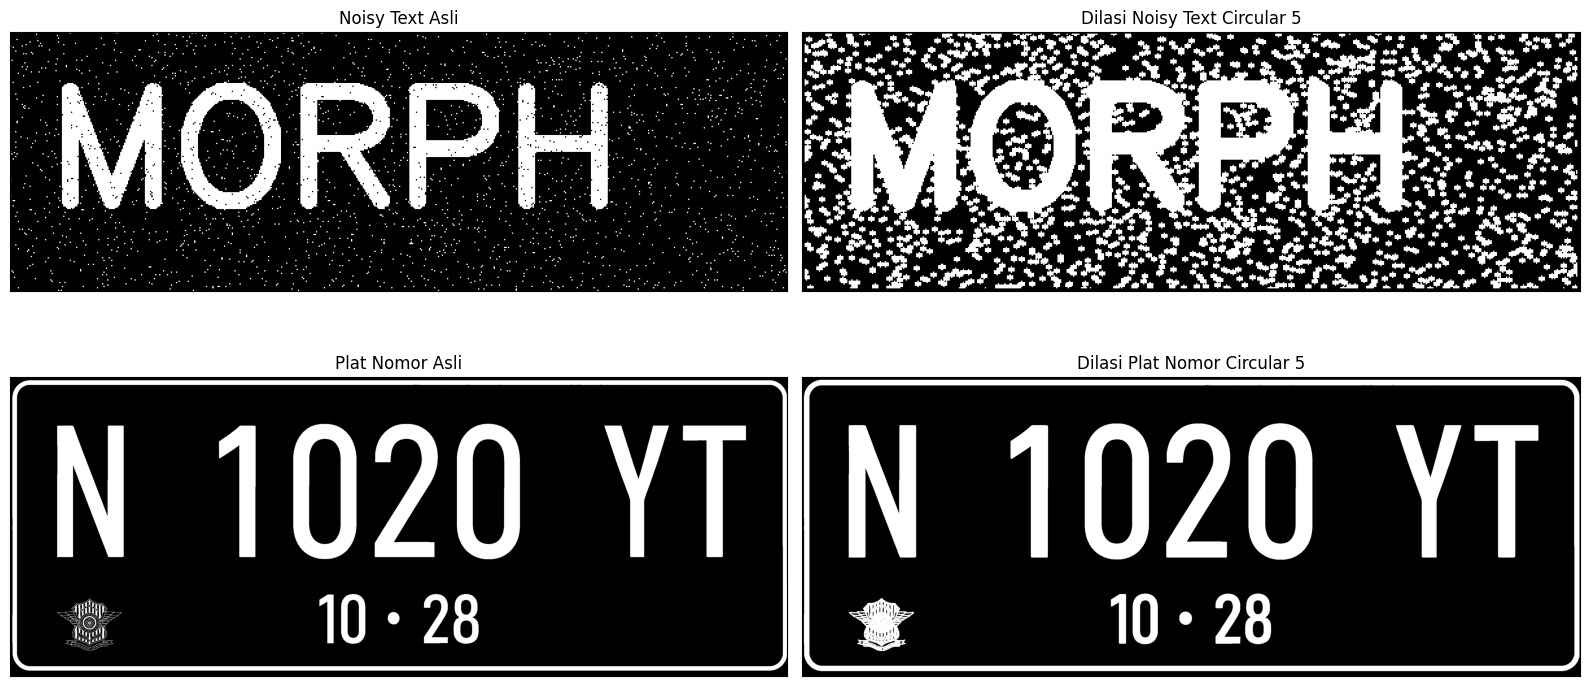

In [111]:
# Dilasi Circular 5 × 5

def dilasi_circular(F, w):
    p, q = F.shape
    imgD = np.zeros((p, q), dtype=np.uint8)

    # Generate Structuring Element berbentuk Circular
    SED = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (w, w))
    constant1 = (w - 1) // 2

    # Proses Dilasi
    for i in range(constant1, p - constant1):
        for j in range(constant1, q - constant1):
            temp = F[
                i - constant1:i + constant1 + 1,
                j - constant1:j + constant1 + 1
            ]
            product = temp * SED
            imgD[i, j] = np.max(product)

    return imgD


print('SED = Circular 5')

img_noisy_text = noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Dilasi pada kedua citra
w = 5
dilasi_noisy_circular5 = dilasi_circular(img_noisy_text, w)
dilasi_plat_circular5 = dilasi_circular(img_plat_nomor, w)

# Menampilkan hasil
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(dilasi_noisy_circular5, cmap='gray')
plt.title('Dilasi Noisy Text Circular 5')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(dilasi_plat_circular5, cmap='gray')
plt.title('Dilasi Plat Nomor Circular 5')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **11. Erosi dengan Structuring Element Rectangle**

SED = Rectangle 3 x 5


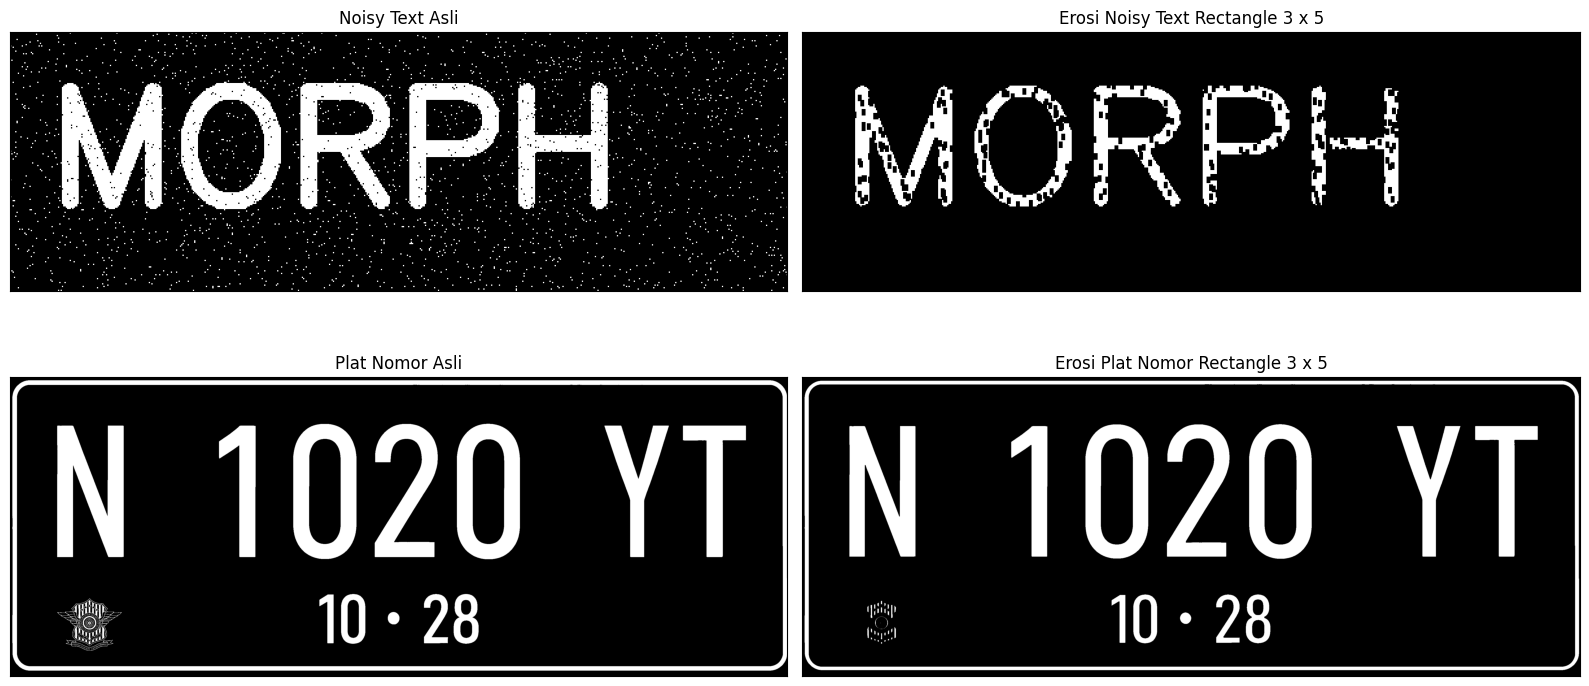

In [112]:
# Erosi Rectangle 3 x 5

def erosi_rectangle(F, p, l):
    m, n = F.shape

    # Membuat Structuring Element berbentuk Rectangle
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))

    tinggi_SE, lebar_SE = SE.shape
    constant_y = tinggi_SE // 2
    constant_x = lebar_SE // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses erosi secara manual
    for i in range(constant_y, m - constant_y):
        for j in range(constant_x, n - constant_x):
            temp = F[
                i - constant_y:i + constant_y + 1,
                j - constant_x:j + constant_x + 1
            ]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


print('SED = Rectangle 3 x 5')

img_noisy_text = noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Erosi pada kedua citra
erosi_noisy_rectangle35 = erosi_rectangle(img_noisy_text, 3, 5)
erosi_plat_rectangle35 = erosi_rectangle(img_plat_nomor, 3, 5)

# Menampilkan citra asli dan hasil erosi
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(erosi_noisy_rectangle35, cmap='gray')
plt.title('Erosi Noisy Text Rectangle 3 x 5')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(erosi_plat_rectangle35, cmap='gray')
plt.title('Erosi Plat Nomor Rectangle 3 x 5')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

SED = Rectangle 5 x 7


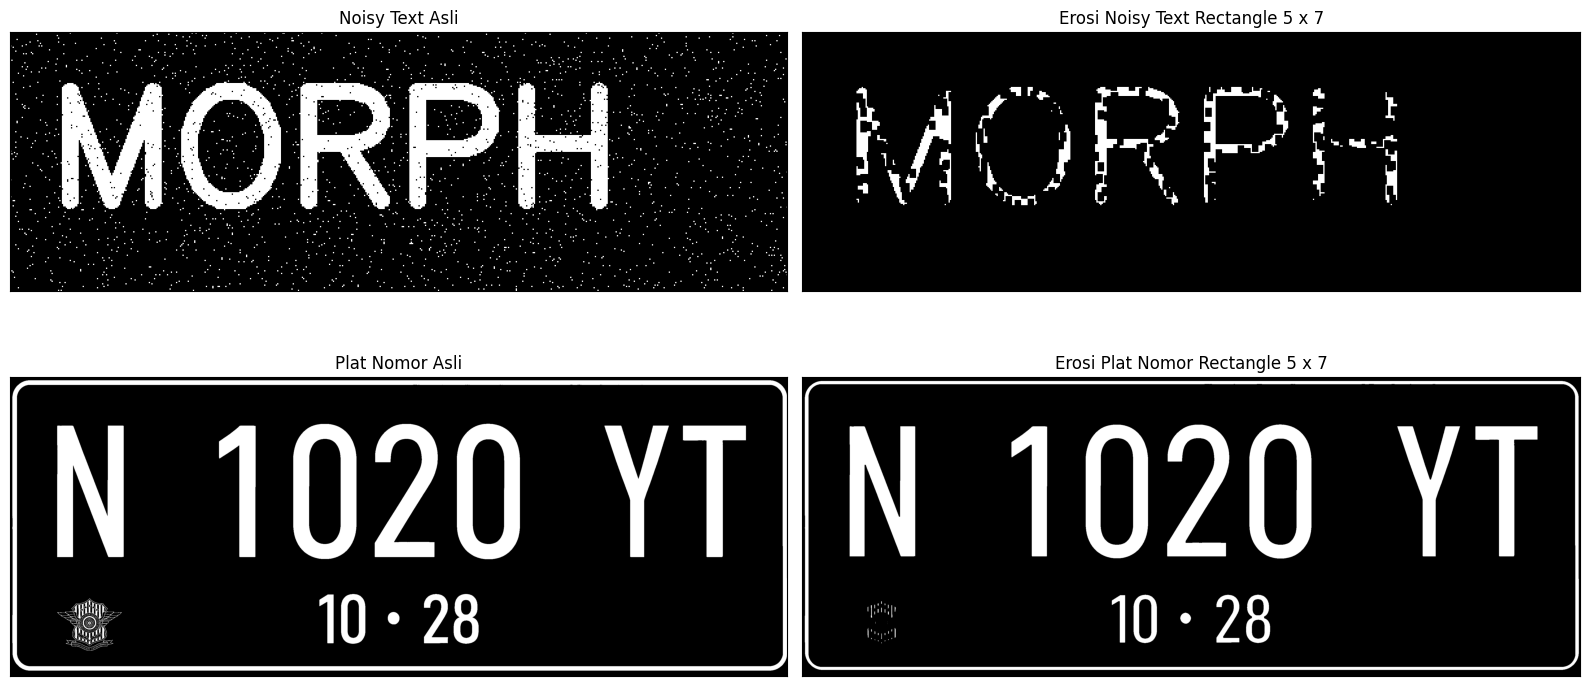

In [113]:
# Erosi Rectangle 5 x 7

def erosi_rectangle(F, p, l):
    m, n = F.shape

    # Membuat Structuring Element berbentuk Rectangle
    SE = cv2.getStructuringElement(cv2.MORPH_RECT, (p, l))

    tinggi_SE, lebar_SE = SE.shape
    constant_y = tinggi_SE // 2
    constant_x = lebar_SE // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses erosi secara manual
    for i in range(constant_y, m - constant_y):
        for j in range(constant_x, n - constant_x):
            temp = F[
                i - constant_y:i + constant_y + 1,
                j - constant_x:j + constant_x + 1
            ]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


print('SED = Rectangle 5 x 7')

img_noisy_text = noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Erosi pada kedua citra
erosi_noisy_rectangle57 = erosi_rectangle(img_noisy_text, 5, 7)
erosi_plat_rectangle57 = erosi_rectangle(img_plat_nomor, 5, 7)

# Menampilkan citra asli dan hasil erosi
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(erosi_noisy_rectangle57, cmap='gray')
plt.title('Erosi Noisy Text Rectangle 5 x 7')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(erosi_plat_rectangle57, cmap='gray')
plt.title('Erosi Plat Nomor Rectangle 5 x 7')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **12. Erosi dengan Structuring Element Line Vertikal**

SE = Line Vertikal 3


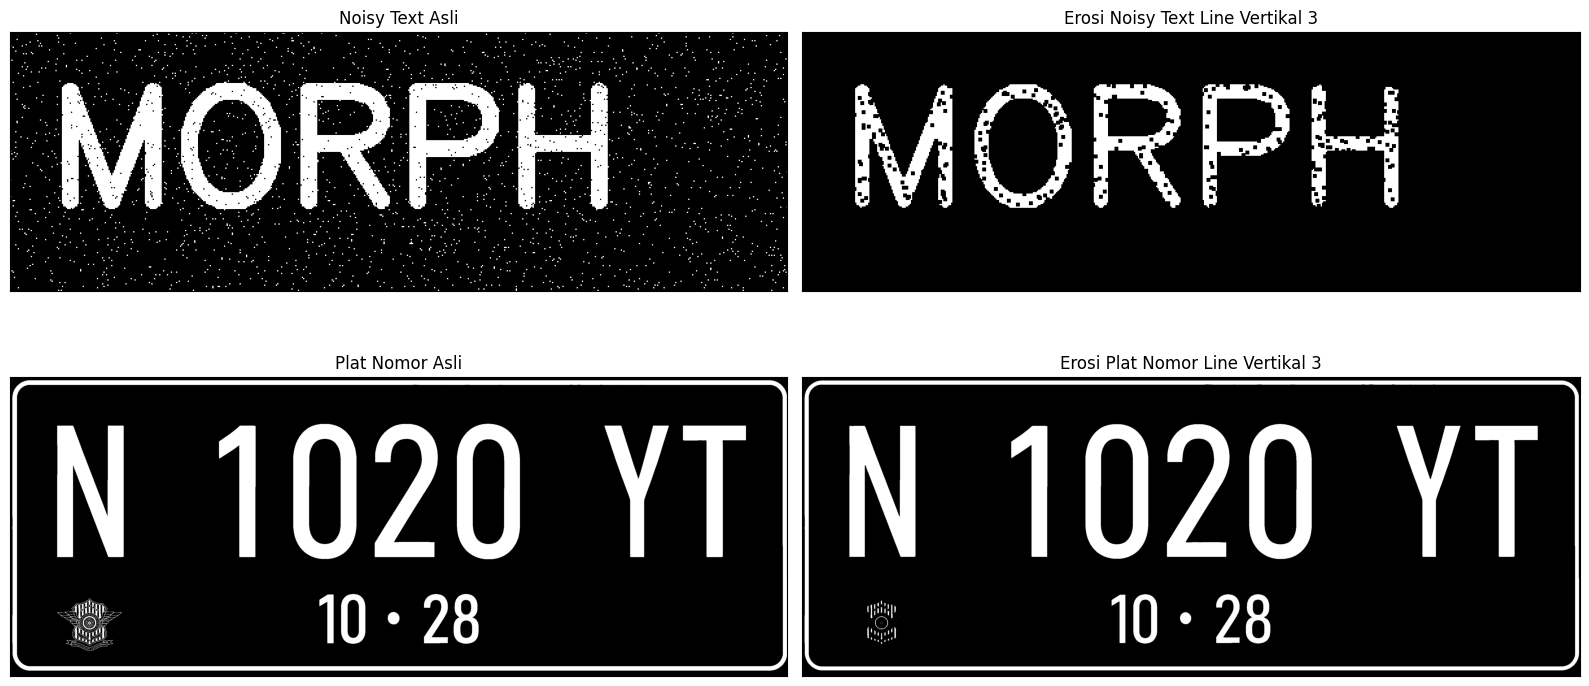

In [114]:
# Erosi Line Vertikal 3

def erosi_line(F, k):
    # Size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[
                i - constant:i + constant + 1,
                j - constant:j + constant + 1
            ]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


print('SE = Line Vertikal 3')

img_noisy_text = noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Erosi pada kedua citra
k = 3
erosi_noisy_line3 = erosi_line(img_noisy_text, k)
erosi_plat_line3 = erosi_line(img_plat_nomor, k)

# Menampilkan hasil
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(erosi_noisy_line3, cmap='gray')
plt.title('Erosi Noisy Text Line Vertikal 3')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(erosi_plat_line3, cmap='gray')
plt.title('Erosi Plat Nomor Line Vertikal 3')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

SE = Line Vertikal 5


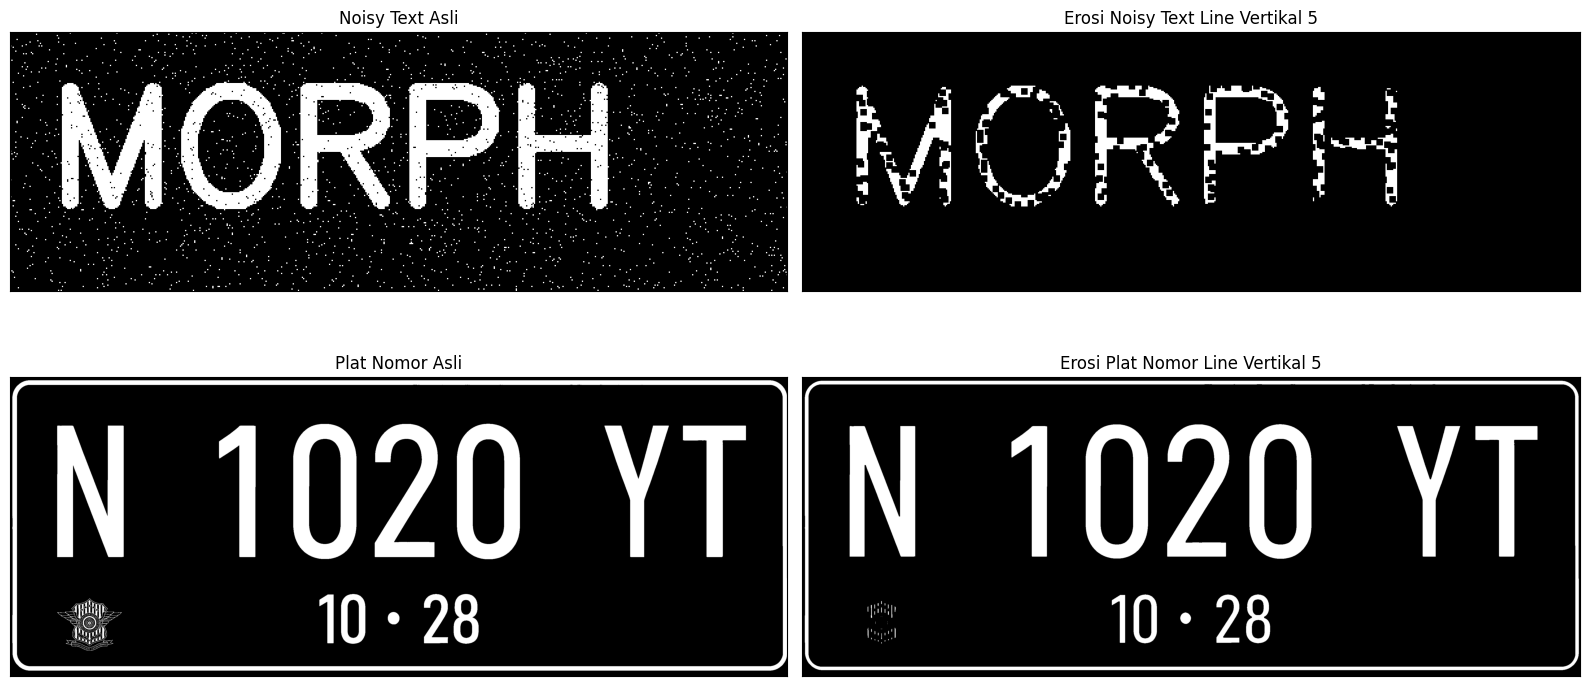

In [115]:
# Erosi Line Vertikal 5

def erosi_line(F, k):
    # Size image
    m, n = F.shape

    # Generate structure element erosi (SE)
    SE = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (1, k))
    constant = (k - 1) // 2

    imgE = np.zeros((m, n), dtype=np.uint8)

    # Proses Erosi
    for i in range(constant, m - constant):
        for j in range(constant, n - constant):
            temp = F[
                i - constant:i + constant + 1,
                j - constant:j + constant + 1
            ]
            product = temp * SE
            imgE[i, j] = np.min(product)

    return imgE


print('SE = Line Vertikal 5')

img_noisy_text = noisy_text.copy()
img_plat_nomor = plat_nomor.copy()

# Erosi pada kedua citra
k = 5
erosi_noisy_line5 = erosi_line(img_noisy_text, k)
erosi_plat_line5 = erosi_line(img_plat_nomor, k)

# Menampilkan hasil
plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_noisy_text, cmap='gray')
plt.title('Noisy Text Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 2)
plt.imshow(erosi_noisy_line5, cmap='gray')
plt.title('Erosi Noisy Text Line Vertikal 5')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 3)
plt.imshow(img_plat_nomor, cmap='gray')
plt.title('Plat Nomor Asli')
plt.xticks([])
plt.yticks([])

plt.subplot(2, 2, 4)
plt.imshow(erosi_plat_line5, cmap='gray')
plt.title('Erosi Plat Nomor Line Vertikal 5')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **13. Transformasi Top-hat dengan Structuring Element 3 × 3**

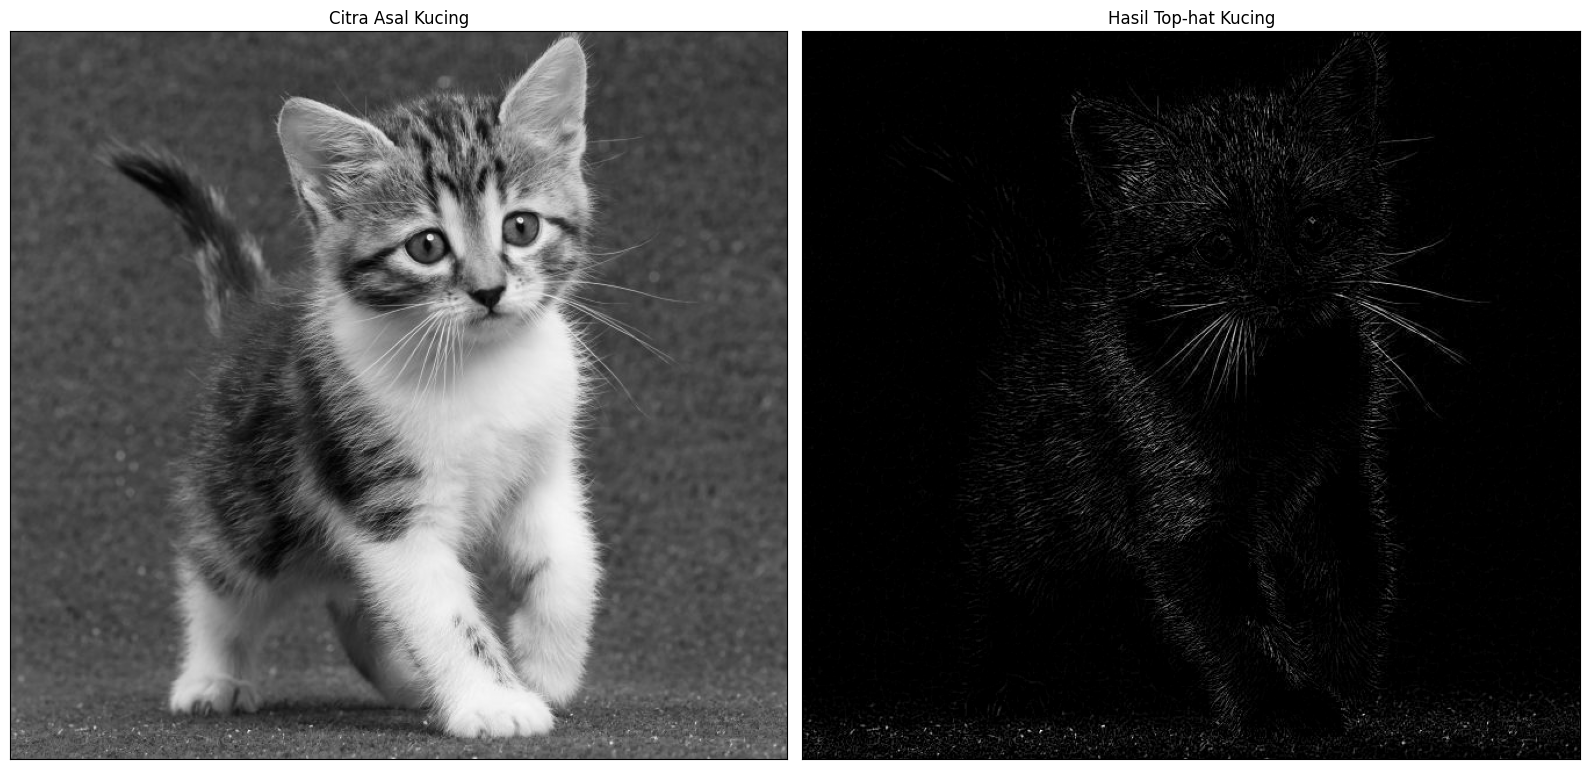

In [116]:
img_kucing = cv2.imread('/content/drive/MyDrive/Semester 5/PCVK/images/kitten01.jpg')
img_kucing = cv2.cvtColor(img_kucing, cv2.COLOR_BGR2GRAY)

# Membuat Structuring Element untuk Top-hat
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT,filterSize)

# Operasi Top-hat
tophat_kucing = cv2.morphologyEx(img_kucing, cv2.MORPH_TOPHAT, kernel)

plt.figure(figsize=(16, 12))

plt.subplot(1, 2, 1)
plt.imshow(img_kucing, cmap='gray')
plt.title('Citra Asal Kucing')
plt.xticks([])
plt.yticks([])

plt.subplot(1, 2, 2)
plt.imshow(tophat_kucing, cmap='gray')
plt.title('Hasil Top-hat Kucing')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **14. Transformasi Black-hat dengan Structuring Element 3 × 3**

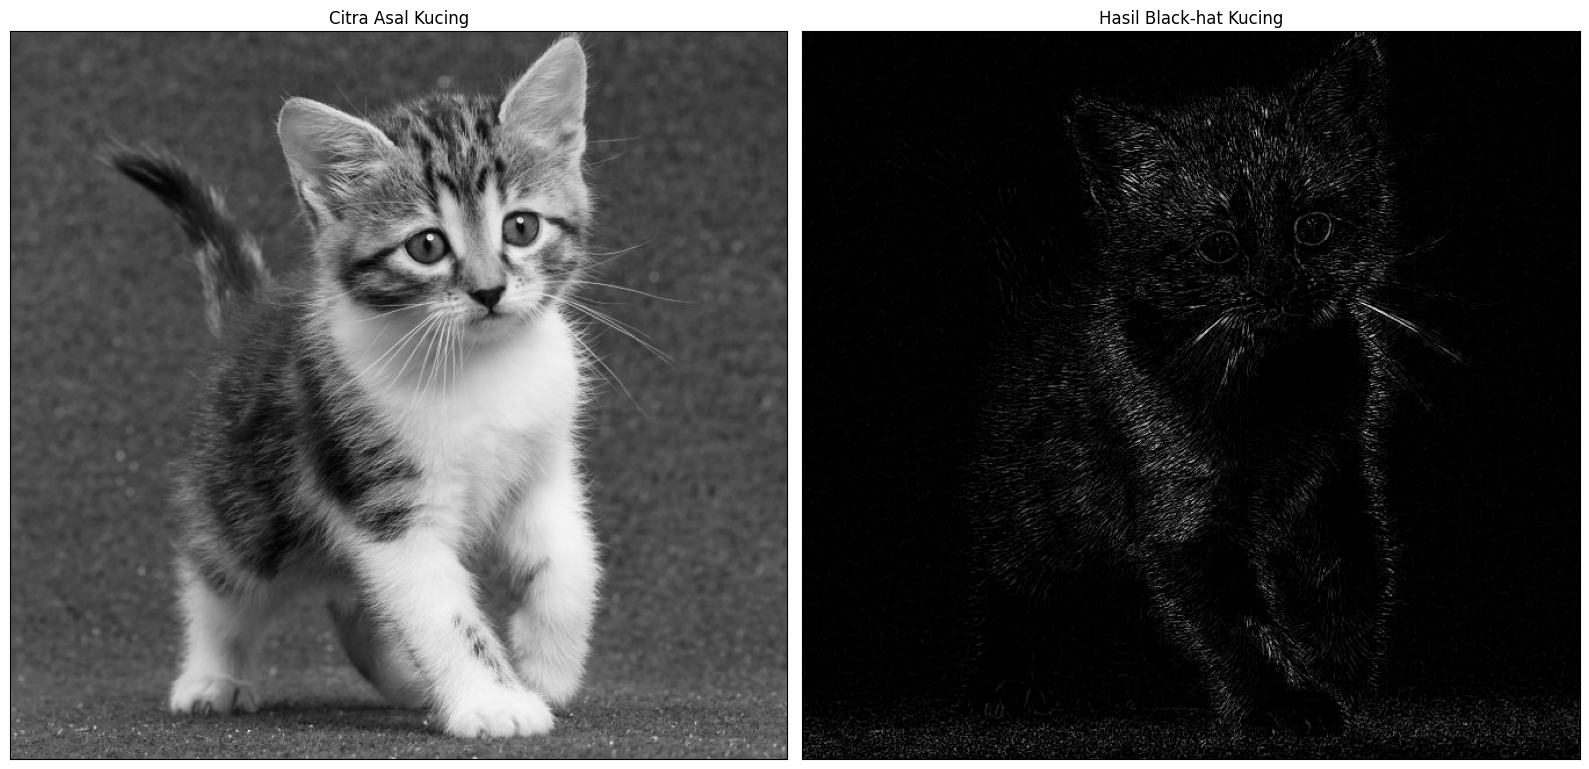

In [117]:
img_kucing = cv2.imread('/content/drive/MyDrive/Semester 5/PCVK/images/kitten01.jpg')
img_kucing = cv2.cvtColor(img_kucing, cv2.COLOR_BGR2GRAY)

# Membuat Structuring Element Black-hat 3 x 3
filterSize = (3, 3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT,filterSize)

# Menerapkan Black-hat
blackhat_kucing = cv2.morphologyEx(img_kucing, cv2.MORPH_BLACKHAT, kernel)


plt.figure(figsize=(16, 12))

plt.subplot(1, 2, 1)
plt.imshow(img_kucing, cmap='gray')
plt.title('Citra Asal Kucing')
plt.xticks([])
plt.yticks([])

plt.subplot(1, 2, 2)
plt.imshow(blackhat_kucing, cmap='gray')
plt.title('Hasil Black-hat Kucing')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

### **15. Membuat Skeleton pada Citra Biner**

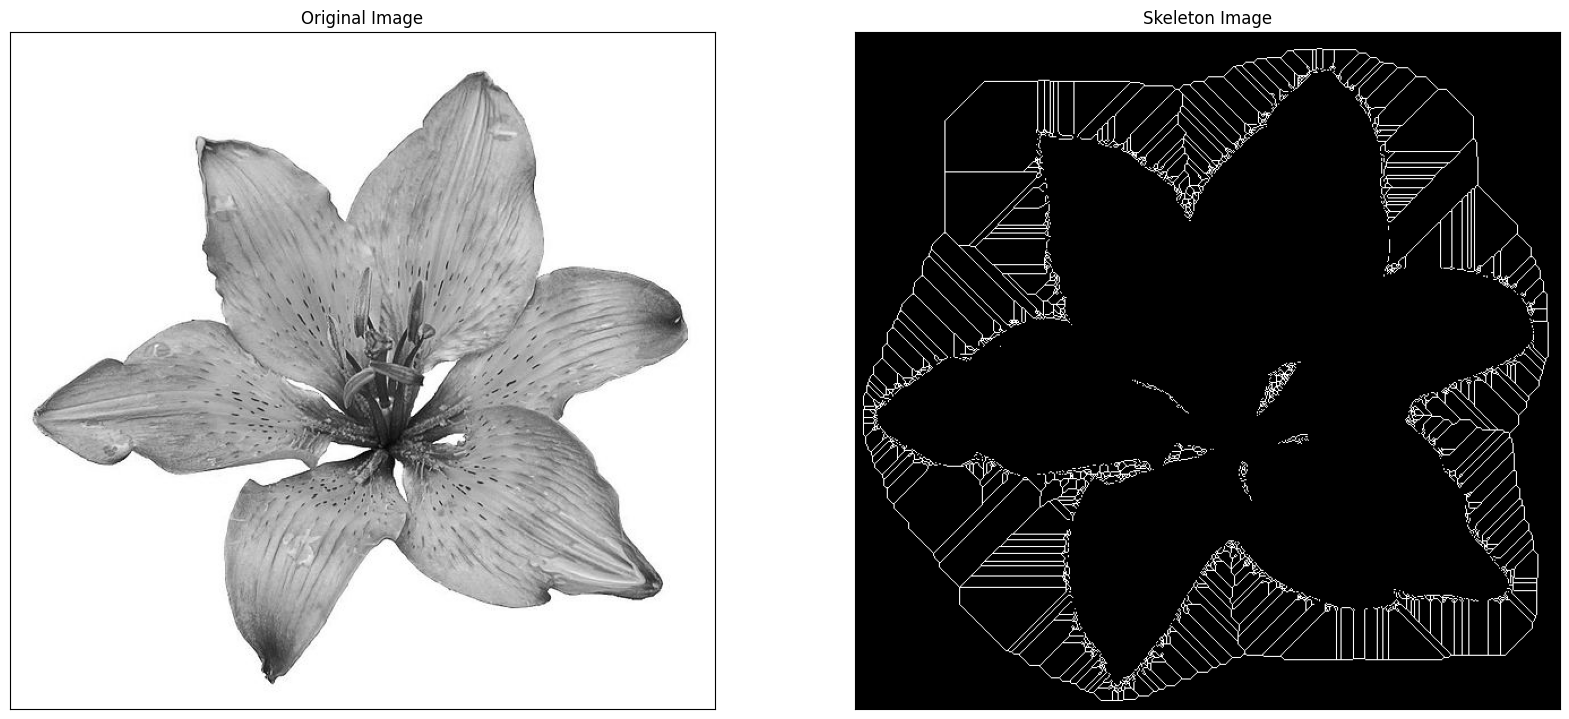

In [118]:
import cv2 as cv
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = cv.imread('/content/drive/MyDrive/Semester 5/PCVK/images/lily.jpg', 0)

# Membuat citra biner
binary = img > filters.threshold_triangle(img)

# True False to one
binary_cp = binary.copy()
binary_cp[binary_cp == True] = 1
binary_cp[binary_cp == False] = 0

# Skeletonize image
skeleton = skeletonize(binary_cp)

plt.figure(figsize=(20, 20))

plt.subplot(121)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.xticks([])
plt.yticks([])

plt.subplot(122)
plt.imshow(skeleton, cmap='gray')
plt.title('Skeleton Image')
plt.xticks([])
plt.yticks([])

plt.show()

### **16. Skeleton pada Citra Hasil Inversi**

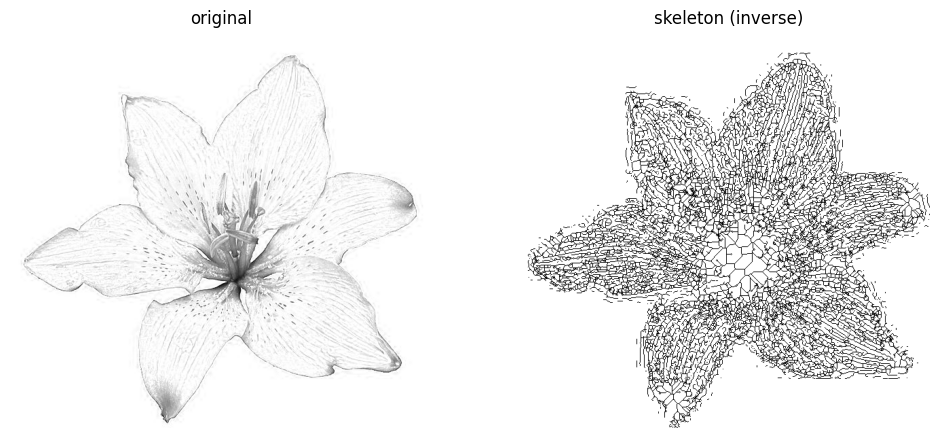

In [119]:
from skimage import io
from matplotlib import pyplot as plt
from skimage import filters
from skimage.morphology import skeletonize

img = io.imread('/content/drive/MyDrive/Semester 5/PCVK/images/lily.jpg')[..., 0]

# Membuat citra biner hasil inversi
binary = img < filters.threshold_triangle(img)

# Skeletonize image
skeleton = skeletonize(binary)

# Print images
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(img, cmap='gray')
ax[0].set_title('original')
ax[0].set_axis_off()

# Note the reversed colormap, gray_r
ax[1].imshow(skeleton, cmap='gray_r')
ax[1].set_title('skeleton (inverse)')
ax[1].set_axis_off()

plt.show()

### **17. Thinning (Penipisan)**

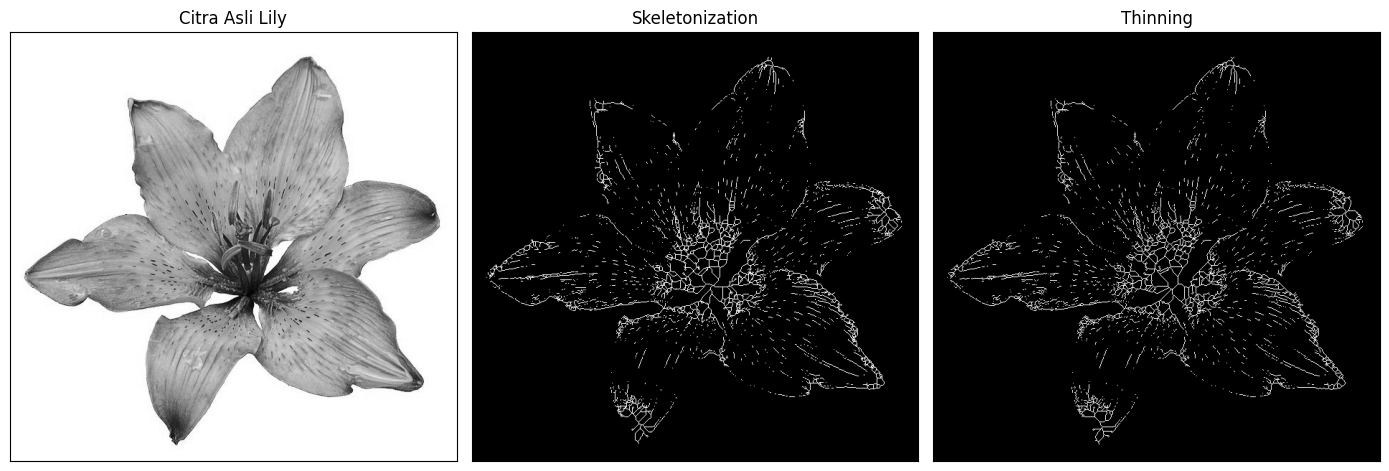

In [120]:
from skimage import img_as_float
from skimage import io, color, morphology
import matplotlib.pyplot as plt

image = img_as_float(color.rgb2gray(io.imread('/content/drive/MyDrive/Semester 5/PCVK/images/lily.jpg')))

# Membuat citra biner
image_binary = image < 0.5

out_skeletonize = morphology.skeletonize(image_binary)
out_thin = morphology.thin(image_binary)

plt.figure(figsize=(14, 10))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Citra Asli Lily')
plt.xticks([])
plt.yticks([])

plt.subplot(1, 3, 2)
plt.imshow(out_skeletonize, cmap='gray')
plt.title('Skeletonization')
plt.xticks([])
plt.yticks([])

plt.subplot(1, 3, 3)
plt.imshow(out_thin, cmap='gray')
plt.title('Thinning')
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

Berdasarkan hasil gambar, metode skeletonization dan thinning sama-sama menghasilkan garis tipis yang mengikuti bentuk bunga lily. Perbedaannya terletak pada proses pembentukan garis tersebut, yaitu skeletonization bertujuan mendapatkan kerangka utama objek, sedangkan thinning menipiskan objek biner dengan tetap mempertahankan bentuk dan keterhubungan strukturnya. Pada hasil percobaan ini, kedua gambar terlihat hampir sama, tetapi keduanya menggunakan metode pemrosesan yang berbeda.